In [5]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [6]:
data = pd.read_csv("ecg.csv", header=None)

print(data.head())
print(data.iloc[:, -1].value_counts())

        0         1         2         3         4         5         6    \
0 -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1 -1.100878 -3.996840 -4.285843 -4.506579 -4.022377 -3.234368 -1.566126   
2 -0.567088 -2.593450 -3.874230 -4.584095 -4.187449 -3.151462 -1.742940   
3  0.490473 -1.914407 -3.616364 -4.318823 -4.268016 -3.881110 -2.993280   
4  0.800232 -0.874252 -2.384761 -3.973292 -4.338224 -3.802422 -2.534510   

        7         8         9    ...       131       132       133       134  \
0 -1.818286 -1.250522 -0.477492  ...  0.792168  0.933541  0.796958  0.578621   
1 -0.992258 -0.754680  0.042321  ...  0.538356  0.656881  0.787490  0.724046   
2 -1.490659 -1.183580 -0.394229  ...  0.886073  0.531452  0.311377 -0.021919   
3 -1.671131 -1.333884 -0.965629  ...  0.350816  0.499111  0.600345  0.842069   
4 -1.783423 -1.594450 -0.753199  ...  1.148884  0.958434  1.059025  1.371682   

        135       136       137       138       139  140  
0  0.2577

In [7]:
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

print("Features:", X.shape)
print("Labels:", np.unique(y))

Features: (4998, 140)
Labels: [0. 1.]


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [9]:
# Assuming label 1 represents normal ECG
NORMAL_LABEL = 1

X_train_normal = X_train[y_train == NORMAL_LABEL]

# Split normal data into training and validation
X_fit, X_val = train_test_split(
    X_train_normal, test_size=0.2, random_state=42
)

In [10]:
scaler = StandardScaler()

X_fit = scaler.fit_transform(X_fit)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Reshape data for CNN
X_fit = X_fit.reshape(-1, 140, 1)
X_val = X_val.reshape(-1, 140, 1)
X_test = X_test.reshape(-1, 140, 1)

In [11]:
model = keras.Sequential([
    keras.Input(shape=(140, 1)),

    # Encoder
    keras.layers.Conv1D(32, 3, activation="relu", padding="same"),
    keras.layers.MaxPooling1D(2, padding="same"),

    keras.layers.Conv1D(16, 3, activation="relu", padding="same"),
    keras.layers.MaxPooling1D(2, padding="same"),

    # Decoder
    keras.layers.Conv1D(16, 3, activation="relu", padding="same"),
    keras.layers.UpSampling1D(2),

    keras.layers.Conv1D(32, 3, activation="relu", padding="same"),
    keras.layers.UpSampling1D(2),

    keras.layers.Conv1D(1, 3, activation="linear", padding="same")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 140, 32)             │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 70, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 70, 16)              │           1,552 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 35, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 35, 16)              │             784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling1d (UpSampling1D)         │ (None, 70, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                    │ (None, 70, 32)              │           1,568 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling1d_1 (UpSampling1D)       │ (None, 140, 32)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_4 (Conv1D)                    │ (None, 140, 1)              │              97 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,129 (16.13 KB)

 Trainable params: 4,129 (16.13 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [13]:
history = model.fit(
    X_fit, X_fit,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, X_val)
)

Epoch 1/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.3206 - mae: 0.3670 - val_loss: 0.1176 - val_mae: 0.2270
Epoch 2/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1050 - mae: 0.2081 - val_loss: 0.0878 - val_mae: 0.1957
Epoch 3/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0813 - mae: 0.1840 - val_loss: 0.0712 - val_mae: 0.1782
Epoch 4/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0696 - mae: 0.1707 - val_loss: 0.0631 - val_mae: 0.1685
Epoch 5/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0631 - mae: 0.1629 - val_loss: 0.0575 - val_mae: 0.1613
Epoch 6/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0588 - mae: 0.1576 - val_loss: 0.0542 - val_mae: 0.1568
Epoch 7/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0559 - mae: 0.1538 - val_loss: 0.0529 - val_mae: 0.1568
Epoch 8/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0534 - mae: 0.1506 - val_loss: 0.0493 - val_mae: 0.1508
Epoch 9/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0510 - mae:

In [14]:
val_predictions = model.predict(X_val)

val_errors = np.mean(
    np.square(X_val - val_predictions), axis=(1, 2)
)

# Set threshold
threshold = np.percentile(val_errors, 99)

print("Threshold:", threshold)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step 
Threshold: 0.20026767917857632


In [15]:
predictions = model.predict(X_test)

errors = np.mean(
    np.square(X_test - predictions), axis=(1, 2)
)

y_pred = (errors > threshold).astype(int)

# Convert actual labels into normal (0) and abnormal (1)
y_actual = (y_test != NORMAL_LABEL).astype(int)

print("Predictions:", y_pred[:20])

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [16]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_actual, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_actual, y_pred, zero_division=0
))


Confusion Matrix:
[[577   7]
 [411   5]]

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.99      0.73       584
           1       0.42      0.01      0.02       416

    accuracy                           0.58      1000
   macro avg       0.50      0.50      0.38      1000
weighted avg       0.51      0.58      0.44      1000



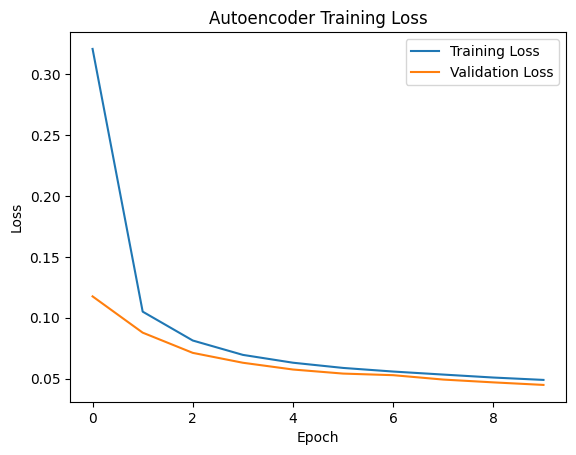

In [17]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

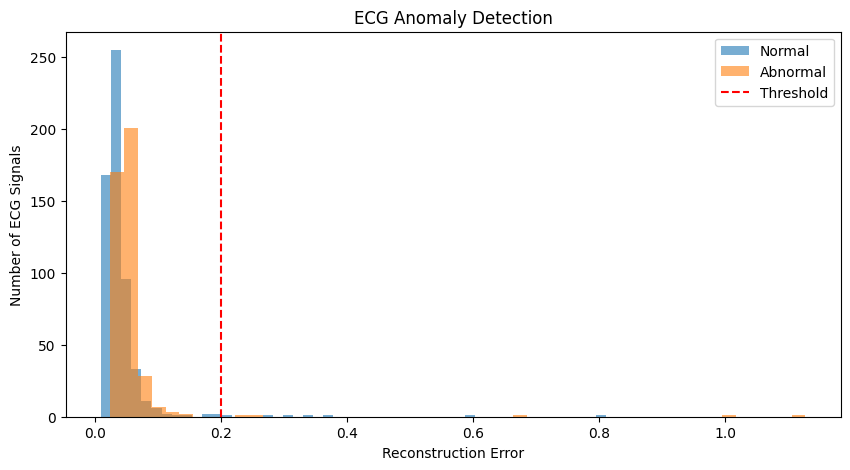

In [18]:
plt.figure(figsize=(10,5))

plt.hist(errors[y_actual == 0], bins=50,
         alpha=0.6, label="Normal")

plt.hist(errors[y_actual == 1], bins=50,
         alpha=0.6, label="Abnormal")

plt.axvline(threshold, color="red",
            linestyle="--", label="Threshold")

plt.title("ECG Anomaly Detection")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of ECG Signals")
plt.legend()
plt.show()